# Suffice: exact repository observations — offline evidence notebook

This self-contained notebook verifies the **completed Suffice 0.13 transport experiment** with Python 3.12 or later and its standard library. No network, GPU, API key, package installation, native executable or model inference is needed.

It preserves the original 103-file corpus, 187 input files, 78 frozen source files, measured build identity, provenance copies, 100 process records and saved summary. The same frozen auditor used by the release recomputes the experiment's recorded output, policy, wire and timing checks. A separate worksheet derives the displayed table and all fifty paired observations directly from elementary process measurements.

**Scope:** the historical run compared complete output bytes. This notebook verifies retained evidence; it does not repeat native execution, regenerate historical timings, decompress stored payload frames, run all regression suites, evaluate Gemma, or prove task-success gains. Any new model-callable bridge has a separate receipt and is not retroactively included in this 100-process study.

The data are the project's own predecessor source corpus and generated measurements. No competition-provided task dataset or model output is embedded. Historical workspace paths remain provenance strings and are not needed as accessible paths. The original MIT license is included.


## 1. Load the bounded local verifier

The exact ZIP and frozen auditor are pinned by SHA-256. Before extraction the verifier checks all paths, types, counts and expansion limits, then uses a fresh temporary directory. During the retained-record audit it rejects Python-audit-visible reads outside the extracted tree and socket/process-launch operations. These observations are validation guards, not a security sandbox for arbitrary Python.


In [1]:
#!/usr/bin/env python3
"""Offline, standard-library-only retained-evidence verification for Suffice 0.13."""
from __future__ import annotations
import argparse
from collections import OrderedDict
import contextlib
from datetime import datetime, timezone
import hashlib
import html
import io
import json
import math
import os
from pathlib import Path, PurePosixPath
import platform
import shutil
import stat
import statistics
import sys
import tempfile
import time
import traceback
import zipfile

EXPECTED_ARCHIVE_SHA256 = "c6ba35462a6e1e997808aa68efda16e75ec5ec8a6e0812e59cc2a3df0ef57eac"
EXPECTED_ARCHIVE_BYTES = 3837891
EXPECTED_FILES = 372
EXPECTED_EXPANDED_BYTES = 27339265
EXPECTED_AUDITOR_SHA256 = "edd889bc32902304a79c2e719174841cc505567281272e703b4cd55831f6a3c9"
EXPECTED_SUMMARY_SHA256 = "b8923214bf1209b681e870fb305294ef00a90d044c829ab4594cc8c087469a04"
ARCHIVE_ROOT = "Suffice_0_13_0_Evidence"
EVIDENCE = "results/transport_v0_13"
MAX_ARCHIVE_BYTES = 8 << 20
MAX_EXPANDED_BYTES = 40 << 20
MAX_MEMBER_BYTES = 2 << 20
EXPECTED_COUNTS = {
    "processes": 100, "complete_output_checks": 4840,
    "verified_rows": 23480, "verified_bytes": 419571140,
    "result_admissions": 1240, "result_evictions": 240, "result_hits": 1680,
    "wire_bytes_received": 639715576, "wire_bytes_sent": 1035660,
}
SCENARIO_ORDER = ("reuse", "pressure", "mixed_queries", "computed", "empty")
_GUARD = {"active": False, "root": None, "read_events": 0,
          "outside_file_events": 0, "network_events": 0, "process_events": 0}


def require(condition, message):
    if not condition:
        raise ValueError(message)


def digest(data):
    return hashlib.sha256(data).hexdigest()


def _observe_audit(event, arguments):
    # This is a validation observation/guard, not a security sandbox for arbitrary Python.
    if not _GUARD["active"]:
        return
    if event.startswith("socket."):
        _GUARD["network_events"] += 1
        raise RuntimeError("network use is outside this offline verifier")
    if event in {"subprocess.Popen", "os.system", "os.exec", "os.posix_spawn",
                 "os.spawn", "os.fork", "os.forkpty", "pty.spawn"}:
        _GUARD["process_events"] += 1
        raise RuntimeError("external process launch is outside this offline verifier")
    if event in {"open", "os.listdir", "os.scandir"} and arguments:
        value = arguments[0]
        if isinstance(value, (str, bytes, os.PathLike)):
            path = Path(os.fsdecode(value)).resolve()
            _GUARD["read_events"] += 1
            if not path.is_relative_to(_GUARD["root"]):
                _GUARD["outside_file_events"] += 1
                raise RuntimeError("auditor attempted a file access outside its extracted bundle")


sys.addaudithook(_observe_audit)


def safe_extract(archive_bytes, destination):
    require(isinstance(archive_bytes, bytes), "archive must be bytes")
    require(len(archive_bytes) == EXPECTED_ARCHIVE_BYTES <= MAX_ARCHIVE_BYTES,
            "archive size differs or exceeds cap")
    require(digest(archive_bytes) == EXPECTED_ARCHIVE_SHA256, "archive SHA-256 differs")
    destination = Path(destination)
    destination.mkdir(parents=False, exist_ok=False)
    destination = destination.resolve()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        entries = archive.infolist()
        require(len(entries) == EXPECTED_FILES, "archive member count differs")
        require(sum(x.file_size for x in entries) == EXPECTED_EXPANDED_BYTES <= MAX_EXPANDED_BYTES,
                "archive expanded size differs or exceeds cap")
        names, folded, targets = set(), set(), []
        for item in entries:
            name, parts = item.filename, item.filename.split("/")
            require(name and "\\" not in name and ":" not in name
                    and all(32 <= ord(c) != 127 for c in name), "unsafe archive path")
            require(not PurePosixPath(name).is_absolute()
                    and all(p not in ("", ".", "..") for p in parts), "noncanonical archive path")
            require(parts[0] == ARCHIVE_ROOT and len(parts) > 1, "unexpected archive root")
            require(name not in names and name.casefold() not in folded,
                    "duplicate or case-colliding archive path")
            require(not item.is_dir() and stat.S_ISREG(item.external_attr >> 16),
                    "only ordinary file members are accepted")
            require(not item.flag_bits & 1, "encrypted archive member")
            require(item.compress_type in (zipfile.ZIP_STORED, zipfile.ZIP_DEFLATED),
                    "unsupported archive compression")
            require(0 <= item.file_size <= MAX_MEMBER_BYTES, "member expanded size exceeds cap")
            target = destination.joinpath(*parts)
            require(target.resolve().is_relative_to(destination), "archive path escapes destination")
            names.add(name); folded.add(name.casefold()); targets.append((item, target))
        for name in names:
            parts = name.split("/")
            require(not any("/".join(parts[:i]) in names for i in range(1, len(parts))),
                    "archive path has a file ancestor")
        expanded = 0
        for item, target in targets:
            target.parent.mkdir(parents=True, exist_ok=True)
            size = 0
            with archive.open(item) as source, target.open("xb") as output:
                while True:
                    chunk = source.read(min(65536, MAX_MEMBER_BYTES - size + 1))
                    if not chunk:
                        break
                    size += len(chunk); expanded += len(chunk)
                    require(size <= item.file_size and size <= MAX_MEMBER_BYTES,
                            "member expanded beyond its declared limit")
                    require(expanded <= MAX_EXPANDED_BYTES, "total expanded size exceeded")
                    output.write(chunk)
            require(size == item.file_size, "member expanded size differs")
        require(expanded == EXPECTED_EXPANDED_BYTES, "actual expanded size differs")
    return destination / ARCHIVE_ROOT


def audit_bundle(archive_bytes):
    """Load the exact frozen auditor, validate saved evidence, return compact observations."""
    with tempfile.TemporaryDirectory(prefix="suffice_013_audit_") as work:
        root = safe_extract(archive_bytes, Path(work) / "unpacked")
        evidence = root / EVIDENCE
        auditor = evidence / "measurement_source/scripts/benchmark_transport_v0_13.py"
        auditor_bytes = auditor.read_bytes()
        require(digest(auditor_bytes) == EXPECTED_AUDITOR_SHA256, "frozen auditor identity differs")
        require(digest((evidence / "SUMMARY.json").read_bytes()) == EXPECTED_SUMMARY_SHA256,
                "saved summary identity differs")
        namespace = {"__name__": "__suffice_frozen_auditor__", "__file__": str(auditor)}
        _GUARD.update(active=True, root=root.resolve(), read_events=0,
                      outside_file_events=0, network_events=0, process_events=0)
        try:
            exec(compile(auditor_bytes, str(auditor), "exec"), namespace)
            summary = namespace["audit"](evidence)
            saved = json.loads((evidence / "SUMMARY.json").read_text(encoding="utf-8"))
            require(summary == saved, "independent audit disagrees with saved summary")
            require(summary["status"] == "passed" and summary["totals"] == EXPECTED_COUNTS,
                    "experiment status or verified counts differ")
            require(summary["corpus_files"] == 103 and summary["input_files"] == 187
                    and summary["frozen_source_files"] == 78 and summary["repeats"] == 10,
                    "evidence inventory or observation-unit count differs")
            run = json.loads((evidence / "RUN.json").read_text(encoding="utf-8"))
            pairs = {}
            for item in run["records"]:
                # The frozen audit already authenticated every member and schedule.
                process = json.loads((evidence / item["path"]).read_text(encoding="utf-8"))
                spec = process["schedule"]
                key = spec["scenario"], spec["repetition"]
                arm = spec["variant"]["name"]
                pairs.setdefault(key, {})[arm] = {
                    "service_ms": process["service_ms"],
                    "raw_wall_ms": process["raw_session_wall_ms"],
                    "oracle_audit_ms": process["oracle_audit_ms"],
                    "wire_bytes_received": process["wire_bytes_received"],
                    "wire_bytes_sent": process["wire_bytes_sent"],
                }
            observations = []
            for scenario in SCENARIO_ORDER:
                for repetition in range(10):
                    arms = pairs[scenario, repetition]
                    require(set(arms) == {"jsonl", "binary"}, "incomplete paired observation")
                    require(arms["jsonl"]["wire_bytes_sent"] == arms["binary"]["wire_bytes_sent"],
                            "paired request bytes differ")
                    observations.append({"scenario": scenario, "repetition": repetition, **arms})
        finally:
            _GUARD["active"] = False
        observed = {k: _GUARD[k] for k in
                    ("read_events", "outside_file_events", "network_events", "process_events")}
        require(observed["outside_file_events"] == observed["network_events"]
                == observed["process_events"] == 0, "offline audit crossed its execution boundary")
        return {
            "schema_version": 1, "status": "passed",
            "scope": "Retained-record audit; historical native outputs/timings are not rerun.",
            "archive_sha256": EXPECTED_ARCHIVE_SHA256,
            "archive_bytes": EXPECTED_ARCHIVE_BYTES, "archive_files": EXPECTED_FILES,
            "expanded_bytes": EXPECTED_EXPANDED_BYTES,
            "audit_script_sha256": EXPECTED_AUDITOR_SHA256,
            "saved_summary_sha256": EXPECTED_SUMMARY_SHA256,
            "run_sha256": summary["run_sha256"], "suite_sha256": summary["suite_sha256"],
            "counts": summary["totals"], "corpus_files": 103, "input_files": 187,
            "frozen_source_files": 78, "paired_blocks_per_scenario": 10,
            "paired_observations": observations,
            "scenarios": summary["scenarios"], "limitations": summary["limitations"],
            "auditor_execution_guard": observed,
            "historical_external_paths_reread": False,
            "native_executable_invoked": False, "model_calls_performed": False,
            "payload_frames_redecompressed": False,
        }


def derive_results(result):
    """Independent arithmetic from elementary paired process observations."""
    table = []
    for scenario in SCENARIO_ORDER:
        pairs = [p for p in result["paired_observations"] if p["scenario"] == scenario]
        require(len(pairs) == 10 and {p["repetition"] for p in pairs} == set(range(10)),
                "paired block inventory differs")
        service = [p["jsonl"]["service_ms"] / p["binary"]["service_ms"] for p in pairs]
        raw = [p["jsonl"]["raw_wall_ms"] / p["binary"]["raw_wall_ms"] for p in pairs]
        wire = [1 - p["binary"]["wire_bytes_received"] / p["jsonl"]["wire_bytes_received"] for p in pairs]
        require(all(math.isfinite(x) and x > 0 for x in service + raw), "invalid timing ratio")
        g = math.exp(sum(math.log(x) for x in service) / len(service))
        raw_g = math.exp(sum(math.log(x) for x in raw) / len(raw))
        expected = result["scenarios"][scenario]["paired_comparisons"]
        for actual, wanted in ((g, expected["jsonl_over_binary_service"]["geometric_mean"]),
                               (statistics.median(service), expected["jsonl_over_binary_service"]["median"]),
                               (raw_g, expected["jsonl_over_binary_raw_wall"]["geometric_mean"]),
                               (statistics.median(wire), expected["response_byte_reduction"]["median"])):
            require(math.isclose(actual, wanted, rel_tol=1e-12, abs_tol=1e-12),
                    "independent paired arithmetic differs")
        table.append({"scenario": scenario, "pairs": len(service), "service_geomean": g,
                      "service_median": statistics.median(service), "service_min": min(service),
                      "service_max": max(service), "pairs_favoring_binary": sum(x > 1 for x in service),
                      "raw_wall_geomean": raw_g, "response_reduction_median": statistics.median(wire),
                      "service_ratios": service})
    return table


def table_markdown(table):
    lines = ["| Scenario | Paired geometric service ratio | Paired median | Binary-favoring blocks | Raw-wall geometric ratio | Median response-byte reduction |",
             "|---|---:|---:|---:|---:|---:|"]
    for r in table:
        lines.append(f"| {r['scenario']} | {r['service_geomean']:.5f} | {r['service_median']:.5f} | "
                     f"{r['pairs_favoring_binary']}/{r['pairs']} | {r['raw_wall_geomean']:.5f} | "
                     f"{100*r['response_reduction_median']:.3f}% |")
    return "\n".join(lines)


def paired_svg(table):
    """A standard-library SVG figure from all fifty paired observations."""
    width, height = 980, 445
    left, right, xmin, xmax = 170, 900, 0.75, 2.75
    x = lambda value: left + (value-xmin)/(xmax-xmin)*(right-left)
    pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="All fifty paired complete-service observations">',
              '<rect width="980" height="445" fill="#fbfcfe"/>',
              '<g font-family="Arial, sans-serif" fill="#172334">',
              '<text x="30" y="35" font-size="23" font-weight="bold">Same completed output, different response transport</text>',
              '<text x="30" y="60" font-size="14">JSONL / Binary complete-service time · each circle is one matched process block</text>']
    for tick in (0.75, 1, 1.5, 2, 2.5, 2.75):
        style = '#8b93a3' if tick == 1 else '#e0e5ec'
        pieces.append(f'<line x1="{x(tick):.2f}" y1="85" x2="{x(tick):.2f}" y2="350" stroke="{style}" stroke-width="{2 if tick==1 else 1}"/>')
        pieces.append(f'<text x="{x(tick):.2f}" y="374" text-anchor="middle" font-size="13">{tick:g}</text>')
    for i, row in enumerate(table):
        y = 112 + 52*i
        pieces.append(f'<text x="150" y="{y+5}" text-anchor="end" font-size="15">{html.escape(row["scenario"].replace("_", " "))}</text>')
        for j, value in enumerate(row['service_ratios']):
            dy = ((j % 5)-2)*3.2 + (1.6 if j >= 5 else -1.6)
            pieces.append(f'<circle cx="{x(value):.2f}" cy="{y+dy:.2f}" r="4.2" fill="#487c9d" fill-opacity="0.65"/>')
        gx, mx = x(row['service_geomean']), x(row['service_median'])
        pieces.append(f'<polygon points="{gx:.2f},{y-9} {gx+7:.2f},{y} {gx:.2f},{y+9} {gx-7:.2f},{y}" fill="#823c80" stroke="#ffffff" stroke-width="1"/>')
        pieces.append(f'<line x1="{mx:.2f}" y1="{y-11}" x2="{mx:.2f}" y2="{y+11}" stroke="#152534" stroke-width="2"/>')
    pieces.extend(['<text x="170" y="402" font-size="13">Above 1 favors Binary. Diamonds: geometric mean. Dark ticks: paired median.</text>',
                   '<text x="170" y="424" font-size="13">Observed blocks, not confidence intervals. Empty output: 4/10 favorable blocks and 2.30% more response bytes.</text>',
                   '</g></svg>'])
    return ''.join(pieces)


def render(mime, value):
    display_function = globals().get("display")
    if callable(display_function):
        display_function({mime: value}, raw=True)
    else:
        print(value)


def print_summary(result):
    c = result["counts"]
    print("PASS: retained 0.13 evidence agrees with the frozen auditor and saved summary.")
    print(f"{result['input_files']} inputs, {result['frozen_source_files']} frozen sources, "
          f"{c['processes']} process records, {c['complete_output_checks']} complete-output checks.")
    print(f"Reconciled {c['verified_rows']:,} rows and {c['verified_bytes']:,} repeated body bytes.")
    print("No native executable, model, network request or historical timing was run.")




## 2. Load the embedded evidence

The next cell embeds the 3,837,891-byte ZIP, also supplied separately as `Suffice_0_13_Offline_Evidence.zip`. All 372 file members are unmodified copies of the completed release evidence plus its license. No external attachment or private file URL is required.


In [2]:
import base64
ARCHIVE_BASE64 = """
...
SwUGAAAAAHQBdAEH0wAAprw5AAAA
"""
ARCHIVE_BYTES = base64.b64decode("".join(ARCHIVE_BASE64.split()), validate=True)
require(len(ARCHIVE_BYTES) == EXPECTED_ARCHIVE_BYTES, "embedded ZIP length differs")
require(digest(ARCHIVE_BYTES) == EXPECTED_ARCHIVE_SHA256, "embedded ZIP hash differs")
print(f"Loaded {len(ARCHIVE_BYTES):,} verified ZIP bytes.")


Loaded 3,837,891 verified ZIP bytes.


## 3. Reconcile the retained experiment

The frozen auditor checks byte identities, the original-body oracle descriptors, the complete schedule, modeled LRU/resource state, independently expected row-wire sizes, cumulative response/request accounting and paired arithmetic. Its recomputed summary must equal the saved `SUMMARY.json` exactly.


In [3]:
AUDIT_RESULT = audit_bundle(ARCHIVE_BYTES)
print_summary(AUDIT_RESULT)


PASS: retained 0.13 evidence agrees with the frozen auditor and saved summary.
187 inputs, 78 frozen sources, 100 process records, 4840 complete-output checks.
Reconciled 23,480 rows and 419,571,140 repeated body bytes.
No native executable, model, network request or historical timing was run.


## 4. Derive the result table independently

For each scenario and repetition, divide JSONL service time by Binary service time **before** aggregation. The geometric mean is `exp(mean(log(paired_ratios)))`. A ratio above one favors Binary. Service time is raw process-session wall time minus explicitly timed oracle/audit intervals; raw-wall ratios are retained alongside it. Response-byte reduction is `1 - Binary_bytes / JSONL_bytes`, so negative values mean increased traffic. The values below come from retained elementary process observations, then are checked against the frozen auditor's results.


In [4]:
RESULT_TABLE = derive_results(AUDIT_RESULT)
render("text/markdown", table_markdown(RESULT_TABLE))


| Scenario | Paired geometric service ratio | Paired median | Binary-favoring blocks | Raw-wall geometric ratio | Median response-byte reduction |
|---|---:|---:|---:|---:|---:|
| reuse | 2.13808 | 2.13298 | 10/10 | 2.03793 | 49.589% |
| pressure | 1.79944 | 1.77344 | 10/10 | 1.69273 | 49.574% |
| mixed_queries | 1.90233 | 1.89121 | 10/10 | 1.83040 | 49.455% |
| computed | 2.02757 | 1.98854 | 10/10 | 1.94736 | 49.589% |
| empty | 1.07010 | 0.99119 | 4/10 | 1.06954 | -2.296% |

## 5. Inspect all paired blocks

Each circle is one matched process block; diamonds are geometric means and dark ticks are paired medians. There are ten blocks per scenario, not 4,840 independent timing replications. The displayed range is an observed range, not a confidence interval. This SVG is constructed from the derived paired observations using only Python strings and arithmetic.


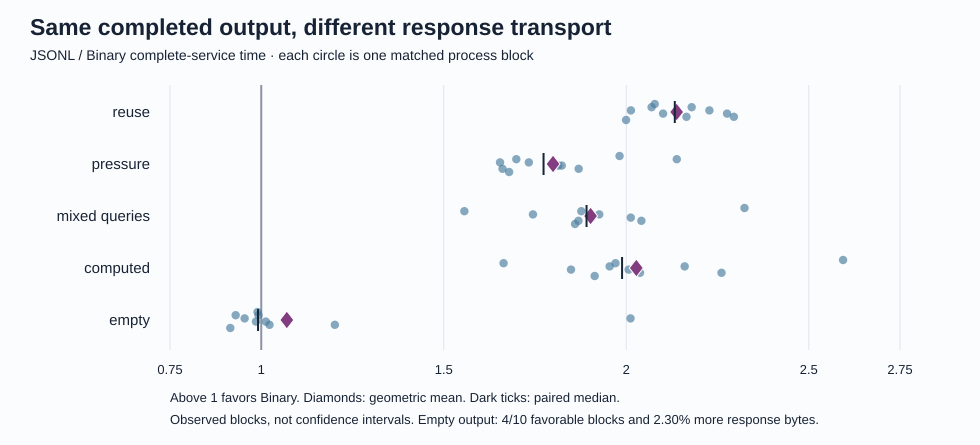

In [5]:
RESULT_SVG = paired_svg(RESULT_TABLE)
render("image/svg+xml", RESULT_SVG)


## Interpretation and limits

The four nonempty scenarios favor Binary in all ten matched blocks and have paired geometric complete-service ratios of approximately 1.799–2.138. This is a local runtime result under the same full-output contract. The empty-output control has only four favorable blocks, a paired median below one, and about 2.30% more response bytes. Its favorable geometric mean does not establish consistent benefit.

The 103 files total 1,460,207 unique plaintext bytes and are divided into twelve logical projects from one corpus. The 419,571,140 compared bytes count repeated deliveries. Both transports use the same binary/client, Capture policy and 16 MiB retained Worker limit. Runs share a pinned Linux CPU without exclusive ownership or cache flushing. Observer effects remain even after subtracting measured audit intervals.

Encoded pipe traffic is not model tokens, RSS or physical disk I/O. Native Windows behavior, whole-process memory ceilings, request deadlines, cross-generation dependency reuse and Gemma issue-resolution gains are outside these observations. The model-facing controller is a separate integration question.

For fresh native work, use the companion source release's documented builder and new output directories. It requires a C++20 toolchain and native Zstandard; some fixture/capture suites also require Python `zstandard`. Those dependencies are not required for this notebook. New measurements are new observations, not a replay of these timestamps.

The accompanying receipt distinguishes local cell-by-cell execution from Kaggle/Jupyter UI execution. Preparing this notebook does not publish it or submit a competition entry.
